# Calibration — fine-tune a forecast model on past Senate races

**What this does.** The settings that move our forecasts the most (how far a race strays from its fundamentals, how far polling averages miss, how much of that miss is shared nationally or regionally, how fat the tails are, how much opinion drifts in the last weeks, incumbency, candidate effects) were judgment calls. This notebook **measures them** on every competitive U.S. Senate race 1998–2022, using FiveThirtyEight's public `raw_polls.csv` (every poll in the final weeks of each race, with the certified result), then:

1. writes the measured values to **`calibration.json` in the chosen model's folder**, translated into that model's own setting names, and
2. (optionally) **re-runs the model** with them and shows the forecast before and after.

**Works with any model in `Models/`.** Set `MODEL_FOLDER` in the first code cell. Settings are matched by name: a model gets only the calibrated values for settings it actually has (`PRIOR_SD`, `SYSTEMATIC_POLL_ERROR_SD`, `CORR_NATIONAL`, `T_DF`, `INCUMBENCY_ADVANTAGE` / `INCUMBENCY_PTS`, …). `Most_Magnificent_Model` (and Marks_Final) read `calibration.json` by themselves. Any other model is run from a **temporary copy** with the values injected after its CONFIG, with its outputs sent to `Final Model/calibration_runs/`, so its own `Output/` is never touched.

| Step | Measures | Becomes |
|---|---|---|
| 2 | Each race's final-weeks polling average vs the result | the error data |
| 3 | National / regional / state pieces of that error; tails | `NATIONAL_ERROR_SD`, `REGIONAL_ERROR_SD`, `STATE_T_DF` (legacy: `CORR_NATIONAL`, `CORR_REGION`, `T_DF`) |
| 4 | How much bigger the error is 3–8 weeks out | `DAILY_DRIFT_SD` |
| 5 | How far results stray from lean + national mood; incumbency; candidate effects | `PRIOR_SD`, `INCUMBENCY_ADVANTAGE`, `CANDIDATE_EFFECT_WEIGHT` |
| 6 | The poll-error floor that makes the model's ranges the right width on past races | `SYSTEMATIC_POLL_ERROR_SD` |
| 7–8 | Translate, write `calibration.json`, re-run the model | — |

All margins are Democrat (or the main non-Republican) minus Republican, in points.


In [1]:
%pip install --quiet numpy pandas scipy matplotlib nbformat nbclient ipykernel


Note: you may need to restart the kernel to use updated packages.


## Settings
Change `MODEL_FOLDER` to calibrate a different model (any folder under `Models/` with a `model.json`). The other settings choose which elections count. Polling errors use every cycle since `POLL_START_CYCLE` (the national piece needs many elections to measure); the fundamentals use only the polarized era since `PRIOR_START_CYCLE`, because ticket-splitting collapsed after 2012 (results stray about 15 points from partisanship in 2002–2008 and about 6–9 since 2016).


In [2]:
# ======================= CHOOSE THE MODEL TO CALIBRATE =======================
MODEL_FOLDER = "Models/Most_Magnificent_Model"  # relative to the repo root, e.g. "Models/Pray_For_The_Floor", "Models/Rylyn_Model"
# =============================================================================

CAL = {
    "POLL_START_CYCLE": 1998,  # polling-error pieces: elections from this year on
    "PRIOR_START_CYCLE": 2014,  # fundamentals (prior SD, incumbency, candidate effects): polarized era only
    "COMPETITIVE_LIMIT": 15,  # use races whose final polling average was within this many points
    "FINAL_WINDOW_DAYS": 21,  # "final-weeks polling average" = polls this many days out or fewer
    "FAR_WINDOW_DAYS": (22, 60),  # earlier window, for the drift estimate
    "HALF_LIFE_DAYS": 7,  # recency half-life (written as RECENCY_HALF_LIFE_DAYS). Team choice Oct 29: 7 days, nearly as
                          #   accurate as the best (5) and steadier in thinly polled races. None = use the most accurate
    "HOUSE_EFFECT_K": 5,  # in-cycle pollster leans (as in Marks_Final) applied to the historical averages; None = off
    "HALF_LIFE_GRID": [3, 5, 7, 10, 14, 21, 30],  # half-lives tested in Step 2b
    "SOURCE_ERROR_CORR": 0.3,  # the model's correlation between prior and poll errors (Pray / Marks default)
    "CANDIDATE_EFFECT_CLIP": 25,  # cap on one candidate's past over-performance (pts), as in Marks_Final
    "SKIP_SETTINGS": [],  # calibrated settings NOT to write, e.g. ["INCUMBENCY_ADVANTAGE"] to keep a model's own choice
    "WRITE_CALIBRATION": True,  # write calibration.json into the model folder
    "RUN_MODEL": True,  # re-run the model afterwards and compare with its last saved forecast
    "RAW_POLLS_URL": "https://raw.githubusercontent.com/fivethirtyeight/data/master/pollster-ratings/raw_polls.csv",
}

import json, os, re, shutil, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq
from IPython.display import display, Markdown

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Data").is_dir() and (p / "Models").is_dir())
FINAL_DIR = REPO_ROOT / "Final Model"
CACHE = FINAL_DIR / "Data_Cache"
CACHE.mkdir(parents=True, exist_ok=True)
MODEL_DIR = (REPO_ROOT / MODEL_FOLDER).resolve()
assert (MODEL_DIR / "model.json").exists(), f"No model.json in {MODEL_DIR}"
MODEL = json.loads((MODEL_DIR / "model.json").read_text())
MODEL_NB = MODEL_DIR / MODEL["notebook"]
print(f"Calibrating {MODEL['name']} ({MODEL['id']}) -> {MODEL_NB.relative_to(REPO_ROOT)}")


Calibrating Marks_Final (marks_final) -> Models/Marks_Final/marks_final.ipynb


## Step 1: Load the historical data
`raw_polls.csv` is downloaded once and saved in `Final Model/Data_Cache/` (used automatically if GitHub is unreachable). It holds polls from roughly the final two months of every Senate, governor, presidential and generic-ballot race since 1998, each with the certified result. Presidential rows also give each state's presidential margin (for partisan lean), and generic-ballot rows give the national House vote. 2024 presidential results come from `Data/pres_2024_results.csv`.


In [3]:
raw_path = CACHE / "raw_polls.csv"
try:
    import urllib.request
    with urllib.request.urlopen(urllib.request.Request(CAL["RAW_POLLS_URL"], headers={"User-Agent": "DACSS-Team5"}), timeout=60) as r:
        raw_path.write_bytes(r.read())
    RAW_SOURCE = "live (GitHub)"
except Exception as e:
    assert raw_path.exists(), f"Download failed ({e}) and there is no saved copy"
    RAW_SOURCE = f"saved copy ({type(e).__name__})"
RAW = pd.read_csv(raw_path, low_memory=False)
RAW["polldate"] = pd.to_datetime(RAW["polldate"], errors="coerce")
leans = pd.read_csv(REPO_ROOT / "Data" / "leans_and_regions.csv", encoding="utf-8-sig")
leans = leans[leans["State"] != "Source"]
REGION_OF = dict(zip(leans["State"].str.strip(), leans["Region"]))
p24 = pd.read_csv(REPO_ROOT / "Data" / "pres_2024_results.csv")
ABBR = {"AL":"Alabama","AK":"Alaska","AZ":"Arizona","AR":"Arkansas","CA":"California","CO":"Colorado","CT":"Connecticut",
        "DE":"Delaware","FL":"Florida","GA":"Georgia","HI":"Hawaii","ID":"Idaho","IL":"Illinois","IN":"Indiana","IA":"Iowa",
        "KS":"Kansas","KY":"Kentucky","LA":"Louisiana","ME":"Maine","MD":"Maryland","MA":"Massachusetts","MI":"Michigan",
        "MN":"Minnesota","MS":"Mississippi","MO":"Missouri","MT":"Montana","NE":"Nebraska","NV":"Nevada","NH":"New Hampshire",
        "NJ":"New Jersey","NM":"New Mexico","NY":"New York","NC":"North Carolina","ND":"North Dakota","OH":"Ohio","OK":"Oklahoma",
        "OR":"Oregon","PA":"Pennsylvania","RI":"Rhode Island","SC":"South Carolina","SD":"South Dakota","TN":"Tennessee",
        "TX":"Texas","UT":"Utah","VT":"Vermont","VA":"Virginia","WA":"Washington","WV":"West Virginia","WI":"Wisconsin",
        "WY":"Wyoming","DC":"DC","US":"US"}
NAME_TO_ABBR = {v: k for k, v in ABBR.items()}
print(f"raw_polls.csv: {len(RAW):,} polls ({RAW_SOURCE}); cycles {RAW['cycle'].min()}-{RAW['cycle'].max()}")
display(RAW["type_simple"].value_counts().rename("polls").to_frame().T)


raw_polls.csv: 20,466 polls (live (GitHub)); cycles 1998-2023


type_simple,Pres-G,Sen-G,Gov-G,House-G,Pres-P,House-G-US,Sen-P,Gov-P,House-P
polls,5867,5006,3537,2957,2035,883,87,49,45


## Step 2: One polling average per race, and its error
Each poll is turned into "non-Republican minus Republican" (races without exactly one Republican among the top two are dropped). Undecideds are split **proportionally**, as the models do. Each race's average uses the polls from its final `FINAL_WINDOW_DAYS` days, weighted like the models: recency (half-life `HALF_LIFE_DAYS`), √sample size (capped at 2,500), 1/√k for a pollster with k polls of the race, 0.6 for partisan sponsors. **Error = actual result − polling average.**

**In-cycle house effects:** with `HOUSE_EFFECT_K` set, every statewide poll (Senate and governor) is first corrected by its pollster's lean that cycle, measured exactly as Marks_Final does (its polls vs other pollsters' polls of the same race, shrunk by k). That cut the error of the final averages from 4.72 to 4.43 pts on these races, so the uncertainty below is measured on the averages the model actually builds.

**Step 2b (recency):** the same averages are rebuilt from every poll up to 60 days out with half-lives from `HALF_LIFE_GRID`, and the half-life with the smallest error becomes `RECENCY_HALF_LIFE_DAYS` (and is used for the rest of this notebook). Recent polls have predicted better than a long memory: the error rises steadily from a 7-day half-life to the models' 21 days. Only competitive races (|average| < `COMPETITIVE_LIMIT`) are kept: lopsided races with big third-party votes (e.g., Maine 2018 with Angus King) produce 30–50 point "errors" that say nothing about close races.


In [4]:
def orient(d):
    """Margin = non-Republican minus Republican. Keeps rows with exactly one Republican among the two candidates."""
    p1, p2 = d["cand1_party"].astype(str).str.upper(), d["cand2_party"].astype(str).str.upper()
    keep = (p1 == "REP") ^ (p2 == "REP")
    d = d[keep].copy()
    opp_first = (p2[keep] == "REP").to_numpy()
    sign = np.where(opp_first, 1.0, -1.0)
    d["opp_pct"] = np.where(opp_first, d["cand1_pct"], d["cand2_pct"]).astype(float)
    d["rep_pct"] = np.where(opp_first, d["cand2_pct"], d["cand1_pct"]).astype(float)
    d["opp_name"] = np.where(opp_first, d["cand1_name"], d["cand2_name"])
    d["rep_name"] = np.where(opp_first, d["cand2_name"], d["cand1_name"])
    d["actual"] = sign * d["margin_actual"].astype(float)
    d["poll_margin"] = (d["opp_pct"] - d["rep_pct"]) * 100 / (d["opp_pct"] + d["rep_pct"])  # proportional undecideds
    return d


def race_averages(d, max_days, min_days=0, half_life=None):
    half_life = half_life or CAL["HALF_LIFE_DAYS"] or 14
    g = d[d["time_to_election"].between(min_days, max_days)].copy()
    g["n"] = g["samplesize"].fillna(600).clip(upper=2500)
    k = g.groupby(["race", "pollster"])["poll_id"].transform("nunique")
    g["w"] = 0.5 ** (g["time_to_election"] / half_life) * np.sqrt(g["n"] / 600) / np.sqrt(k)
    g["w"] *= np.where(g["partisan"].notna(), 0.6, 1.0)
    g["wm"], g["wd"], g["w2"] = g["w"] * g["poll_margin"], g["w"] * g["time_to_election"], g["w"] ** 2
    a = g.groupby("race").agg(sw=("w", "sum"), swm=("wm", "sum"), swd=("wd", "sum"), sw2=("w2", "sum"), n_polls=("poll_id", "size"),
                              cycle=("cycle", "first"), location=("location", "first"), actual=("actual", "first"),
                              opp_name=("opp_name", "first"), rep_name=("rep_name", "first"), type=("type_simple", "first"))
    a["avg"], a["mean_days"], a["n_eff"] = a["swm"] / a["sw"], a["swd"] / a["sw"], a["sw"] ** 2 / a["sw2"]
    a["error"] = a["actual"] - a["avg"]
    return a.drop(columns=["sw", "swm", "swd", "sw2"]).reset_index()


def in_cycle_leans(g, k, hl, iters=3):
    """Each pollster's lean in one cycle: its polls vs the same race's weighted average WITHOUT that pollster, summed and
    shrunk (sum / (n + k)); repeated so the comparison polls are corrected too. Same rule as Marks_Final (prior 0 here)."""
    w = 0.5 ** (g["time_to_election"] / hl) * np.sqrt(g["samplesize"].fillna(600).clip(upper=2500) / 600)
    m, use = g["poll_margin"], g["partisan"].isna()
    lean = pd.Series(0.0, index=g.index)
    for _ in range(iters):
        x = m - lean
        tot, tw = (w * x).groupby(g["race"]).transform("sum"), w.groupby(g["race"]).transform("sum")
        own, ow = (w * x).groupby([g["race"], g["pollster"]]).transform("sum"), w.groupby([g["race"], g["pollster"]]).transform("sum")
        res = (m - (tot - own) / (tw - ow).where(tw - ow > 0)).where(use)
        s = res.groupby(g["pollster"]).agg(["sum", "count"])
        lean = (g["pollster"].map(s["sum"] / (s["count"] + k)).fillna(0.0)).where(use, 0.0)
    return lean


SG = orient(RAW[RAW["type_simple"].isin(["Sen-G", "Gov-G"])])  # statewide polls (Senate + governor) for pollster leans
SG = SG[SG["time_to_election"] <= 60]
if CAL["HOUSE_EFFECT_K"] is not None:
    SG["poll_margin"] = SG["poll_margin"] - pd.concat(
        [in_cycle_leans(g, CAL["HOUSE_EFFECT_K"], CAL["HALF_LIFE_DAYS"] or 7) for _, g in SG.groupby("cycle")])
SEN = SG[SG["type_simple"] == "Sen-G"].copy()

# ---- Step 2b: which recency half-life gives the most accurate averages? (all polls up to 60 days out) ----
_comp = race_averages(SEN, CAL["FINAL_WINDOW_DAYS"], half_life=14)
_comp = _comp[(_comp["avg"].abs() < CAL["COMPETITIVE_LIMIT"]) & (_comp["cycle"] >= CAL["POLL_START_CYCLE"])]["race"]
hl_rows = []
for hl in CAL["HALF_LIFE_GRID"]:
    a_ = race_averages(SEN, 60, half_life=hl)
    a_ = a_[a_["race"].isin(_comp)]
    hl_rows.append({"half-life (days)": hl, "RMSE (pts)": float(np.sqrt((a_["error"] ** 2).mean())), "mean abs error": float(a_["error"].abs().mean())})
HL_TABLE = pd.DataFrame(hl_rows).set_index("half-life (days)")
BEST_HALF_LIFE = int(HL_TABLE["RMSE (pts)"].idxmin())
display(HL_TABLE.round(3).T)
if CAL["HALF_LIFE_DAYS"] is None:
    CAL["HALF_LIFE_DAYS"] = BEST_HALF_LIFE
print(f"Most accurate half-life: {BEST_HALF_LIFE} days; using {CAL['HALF_LIFE_DAYS']} days (RECENCY_HALF_LIFE_DAYS)"
      + (f"; polls corrected for in-cycle pollster leans (k = {CAL['HOUSE_EFFECT_K']})" if CAL["HOUSE_EFFECT_K"] is not None else ""))

ALL_RACES = race_averages(SEN, CAL["FINAL_WINDOW_DAYS"])
RACES = ALL_RACES[(ALL_RACES["avg"].abs() < CAL["COMPETITIVE_LIMIT"]) & (ALL_RACES["cycle"] >= CAL["POLL_START_CYCLE"])].copy()
RACES["region"] = RACES["location"].map(lambda a: REGION_OF.get(ABBR.get(a, a)))
RACES = RACES.dropna(subset=["region"])
print(f"{len(ALL_RACES)} Senate races with final-weeks polls -> {len(RACES)} competitive races, {RACES['cycle'].nunique()} cycles")
print(f"Polling-average error: mean {RACES['error'].mean():+.2f} (+ = Democrats beat their polls), SD {RACES['error'].std():.2f}, "
      f"mean absolute {RACES['error'].abs().mean():.2f} pts")


half-life (days),3,5,7,10,14,21,30
RMSE (pts),4.462,4.424,4.427,4.457,4.506,4.579,4.644
mean abs error,3.545,3.472,3.446,3.458,3.495,3.556,3.602


Most accurate half-life: 5 days; using 7 days (RECENCY_HALF_LIFE_DAYS); polls corrected for in-cycle pollster leans (k = 5)
391 Senate races with final-weeks polls -> 179 competitive races, 15 cycles
Polling-average error: mean -0.70 (+ = Democrats beat their polls), SD 4.42, mean absolute 3.47 pts


## Step 3: How the error splits into national, regional and state pieces
Each race's error = **national** piece (shared by every race that year) + **regional** piece (shared within a Census region that year) + **state** piece. Each piece's size is estimated by the method of moments, removing the part of each group average that is just the noise of averaging a few races:

- var(yearly average error) = σ²_national + (within-year variance ÷ races that year)
- var(year × region average) = σ²_regional + (within-region variance ÷ races in it)
- σ²_state = the rest

The state piece is then split into a **floor** that doesn't shrink with more polls and a part that does: state² = floor² + single-poll SD² ÷ n_eff (least squares). **Tails:** excess kurtosis of the state pieces gives a Student-t df (df = 4 + 6 ÷ excess kurtosis). A 90% bootstrap range (resampling whole election years) shows how precisely the national piece is known.

**Should the forecast be shifted for poll bias?** Only if a cycle's miss can be predicted. The test below predicts each cycle's average miss from earlier cycles (no correction, long-run average, last 3 cycles, last cycle). Through 2022, "no correction" was the most accurate: misses don't persist (2020's R-ward miss was followed by 2022's D-ward one). So no shift is applied. Instead, the national piece is measured **around zero** rather than around the average miss, so the simulation's spread includes the chance of a miss in either direction of the size seen historically.


,RMSE predicting each cycle's national miss
no correction (0),2.64
average of all earlier cycles,2.76
average of the previous 3 cycles,2.90
previous cycle,3.82


Correlation of a cycle's miss with the previous 3 cycles' average: -0.18
National piece: 2.43 around its average (-0.70); 2.52 around zero -> NATIONAL_ERROR_SD


,SD (pts)
national (shared by all races),2.43
regional (shared within a region),1.51
state (race only),3.11
of which: floor (doesn't shrink with more polls),1.73
single-poll SD (shrinks with √n_eff),3.30
total,4.42


National piece 90% bootstrap range: 1.7-2.9 pts | state-piece excess kurtosis 0.87 -> t df ≈ 11


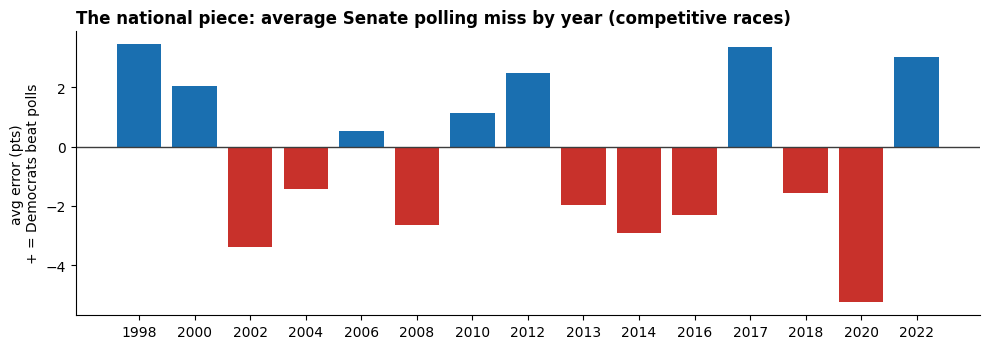

In [5]:
def decompose(r):
    r = r.copy()
    cyc = r.groupby("cycle")["error"]
    r["res1"] = r["error"] - cyc.transform("mean")
    reg = r.groupby(["cycle", "region"])["res1"]
    r["res2"] = r["res1"] - reg.transform("mean")
    within = r["res1"].var()
    k = r.groupby("cycle").size()
    sN2 = max(cyc.mean().var() - (within / k).mean(), 0.0)
    kr = r.groupby(["cycle", "region"]).size()
    multi = kr[kr > 1].index
    v_state = r.set_index(["cycle", "region"]).loc[multi, "res2"].var()
    sR2 = max(reg.mean().loc[multi].var() - (v_state / kr.loc[multi]).mean(), 0.0)
    return r, {"national": np.sqrt(sN2), "regional": np.sqrt(sR2), "state": np.sqrt(max(within - sR2, 0.0)), "total": r["error"].std()}


RES3, PIECES = decompose(RACES)
X = np.column_stack([np.ones(len(RES3)), 1 / RES3["n_eff"]])
b, *_ = np.linalg.lstsq(X, RES3["res2"] ** 2, rcond=None)
STATE_FLOOR, SINGLE_POLL_SD = np.sqrt(max(b[0], 0)), np.sqrt(max(b[1], 0))
z = (RES3["res2"] - RES3["res2"].mean()) / RES3["res2"].std()
EXCESS_KURT = float((z ** 4).mean() - 3)
STATE_DF = float(np.clip(4 + 6 / EXCESS_KURT, 4, 30)) if EXCESS_KURT > 0 else 30.0

rng = np.random.default_rng(2026)
cycles = RACES["cycle"].unique()
boot = []
for _ in range(400):
    pick = rng.choice(cycles, len(cycles))
    bs = pd.concat([RACES[RACES["cycle"] == c].assign(cycle=i) for i, c in enumerate(pick)])
    boot.append(decompose(bs)[1]["national"])
NAT_RANGE = np.percentile(boot, [5, 95])

# ---- Can a polling miss be predicted from earlier cycles? ----
cm_ = RACES[RACES["cycle"] % 2 == 0].groupby("cycle")["error"].mean()
ok_ = cm_.rolling(3).mean().shift(1).notna()
preds = {"no correction (0)": 0 * cm_[ok_], "average of all earlier cycles": cm_.expanding().mean().shift(1)[ok_],
         "average of the previous 3 cycles": cm_.rolling(3).mean().shift(1)[ok_], "previous cycle": cm_.shift(1)[ok_]}
BIAS_TEST = pd.Series({k: float(np.sqrt(((cm_[ok_] - v) ** 2).mean())) for k, v in preds.items()}, name="RMSE predicting each cycle's national miss")
BIAS_CORR = float(np.corrcoef(cm_.rolling(3).mean().shift(1)[ok_], cm_[ok_])[0, 1])
display(BIAS_TEST.round(2).to_frame())
print(f"Correlation of a cycle's miss with the previous 3 cycles' average: {BIAS_CORR:+.2f}")
# No bias correction is applied, so the national error the simulation needs is the miss around ZERO, not around the average miss
NATIONAL_ABOUT_ZERO = float(np.sqrt(PIECES["national"] ** 2 + RACES["error"].mean() ** 2))
print(f"National piece: {PIECES['national']:.2f} around its average ({RACES['error'].mean():+.2f}); "
      f"{NATIONAL_ABOUT_ZERO:.2f} around zero -> NATIONAL_ERROR_SD")

display(pd.DataFrame({
    "SD (pts)": [PIECES["national"], PIECES["regional"], PIECES["state"], STATE_FLOOR, SINGLE_POLL_SD, PIECES["total"]],
}, index=["national (shared by all races)", "regional (shared within a region)", "state (race only)",
          "   of which: floor (doesn't shrink with more polls)", "   single-poll SD (shrinks with √n_eff)", "total"]).round(2))
print(f"National piece 90% bootstrap range: {NAT_RANGE[0]:.1f}-{NAT_RANGE[1]:.1f} pts | state-piece excess kurtosis "
      f"{EXCESS_KURT:.2f} -> t df ≈ {STATE_DF:.0f}")

cm = RACES.groupby("cycle")["error"].mean()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(cm.index.astype(str), cm.values, color=np.where(cm.values > 0, "#1A6FB0", "#C8312B"))
ax.axhline(0, color="#3C3C3C", lw=1)
ax.set_ylabel("avg error (pts)\n+ = Democrats beat polls")
ax.set_title("The national piece: average Senate polling miss by year (competitive races)", loc="left", fontweight="bold")
ax.spines[["right", "top"]].set_visible(False)
fig.tight_layout(); plt.show()


## Step 4: Drift — how much opinion moves in the last weeks
The same races' polling averages from 3–8 weeks out (`FAR_WINDOW_DAYS`) miss by more than the final-weeks averages. Part of that is fewer polls (corrected for using the Step 3 floor and single-poll SD); the rest is opinion moving. With the models' random-walk shape (extra variance = drift² × days), drift² = (extra variance far − extra variance near) ÷ (difference in average days out).


In [6]:
far = race_averages(SEN, CAL["FAR_WINDOW_DAYS"][1], CAL["FAR_WINDOW_DAYS"][0])
far = far[far["race"].isin(RACES["race"])]
near = RACES.set_index("race").loc[far["race"]]
floor2 = PIECES["national"] ** 2 + PIECES["regional"] ** 2 + STATE_FLOOR ** 2
excess = lambda r_: r_["error"].var() - (floor2 + SINGLE_POLL_SD ** 2 * (1 / r_["n_eff"]).mean())
days = far["mean_days"].mean() - near["mean_days"].mean()
DRIFT = float(np.sqrt(max(excess(far) - excess(near), 0) / days))
print(f"{len(far)} races polled both windows: error SD {far['error'].std():.2f} pts at ~{far['mean_days'].mean():.0f} days out vs "
      f"{near['error'].std():.2f} at ~{near['mean_days'].mean():.0f} days -> DAILY_DRIFT_SD ≈ {DRIFT:.2f} pts per √day "
      f"(5 days left: ±{DRIFT * np.sqrt(5):.1f} pts)")


173 races polled both windows: error SD 5.82 pts at ~31 days out vs 4.41 at ~8 days -> DAILY_DRIFT_SD ≈ 0.76 pts per √day (5 days left: ±1.7 pts)


## Step 5: The fundamentals prior — how far results stray from lean + national mood
For every Senate race since `PRIOR_START_CYCLE` the prior is rebuilt the way the models build it, with only information available before the election:

- **lean** = average of the state's presidential margin minus the national margin in the last two presidential elections *before* that year (like the Cook PVI the models use)
- **national mood** = the final-weeks **generic-ballot polling average** (two-party, like the models), so the national mood's own error is included
- **incumbency** = +1 / −1 if a Democratic / Republican senator who won this seat in the last 6 years is running (found by matching names to earlier races in the file)
- **candidate effect** = each nominee's over-performance in their most recent Senate or governor race in the state (last 8 years): their margin − (lean that year + national House vote that year), summed for both nominees and capped at ±`CANDIDATE_EFFECT_CLIP` (Marks_Final's `candidate_history.csv` rule)

Regressing (actual − lean − mood) on incumbency and the candidate effect gives **`INCUMBENCY_ADVANTAGE`** and **`CANDIDATE_EFFECT_WEIGHT`**; the spread of what's left is **`PRIOR_SD`**.


In [7]:
def surname(n):
    parts = [p for p in re.sub(r"[^a-z \-]", "", str(n).lower()).split() if p not in ("jr", "sr", "ii", "iii", "iv")]
    return parts[-1] if parts else ""


pres = orient(RAW[RAW["type_simple"] == "Pres-G"].drop_duplicates("race"))
PRES = pres.pivot_table(index="location", columns="cycle", values="actual", aggfunc="first")
PRES[2024] = pd.Series((p24["Harris_pct"] - p24["Trump_pct"]).values, index=p24["State"].map(NAME_TO_ABBR)).reindex(PRES.index)
house = orient(RAW[RAW["type_simple"] == "House-G-US"])
HOUSE_ACTUAL = house.drop_duplicates("cycle").set_index("cycle")["actual"]
GB_POLLS = race_averages(house, CAL["FINAL_WINDOW_DAYS"]).set_index("cycle")["avg"]


def lean(loc, year, strict=True):
    yrs = [y for y in sorted(PRES.columns) if (y < year if strict else y <= year)][-2:]
    vals = [PRES.loc[loc, y] - PRES.loc["US", y] for y in yrs if loc in PRES.index and pd.notna(PRES.loc[loc, y])]
    return float(np.mean(vals)) if vals else np.nan


hist = orient(RAW[RAW["type_simple"].isin(["Sen-G", "Gov-G"])]).drop_duplicates("race")
hist["overperf"] = [a - (lean(l, y, strict=False) + HOUSE_ACTUAL.get(y, np.nan))
                    for a, l, y in zip(hist["actual"], hist["location"], hist["cycle"])]
rows = []
for _, x in ALL_RACES.iterrows():
    y, loc = int(x["cycle"]), x["location"]
    if y < CAL["PRIOR_START_CYCLE"] or y % 2 or y not in GB_POLLS.index or np.isnan(lean(loc, y)):
        continue
    prev = hist[(hist["location"] == loc) & (hist["cycle"] < y) & (hist["cycle"] >= y - 8)]
    eff, inc = [], 0.0
    for side, name in (("opp", x["opp_name"]), ("rep", x["rep_name"])):
        k = surname(name)
        m = prev[(prev["opp_name"].map(surname) == k) | (prev["rep_name"].map(surname) == k)].sort_values("cycle")
        if len(m) and pd.notna(m["overperf"].iloc[-1]):
            eff.append((m["race"].iloc[-1], float(np.clip(m["overperf"].iloc[-1], -CAL["CANDIDATE_EFFECT_CLIP"], CAL["CANDIDATE_EFFECT_CLIP"]))))
        won = m[(m["type_simple"] == "Sen-G") & (m["cycle"] >= y - 6)]
        if len(won) and ((won["actual"].iloc[-1] > 0) if side == "opp" else (won["actual"].iloc[-1] < 0)):
            inc = 1.0 if side == "opp" else -1.0
    cand = sum(v for _, v in dict(eff).items())  # a rematch's shared earlier race counts once
    rows.append({"race": x["race"], "cycle": y, "lean": lean(loc, y), "mood": GB_POLLS.loc[y], "incumbent": inc, "cand": cand,
                 "poll_avg": x["avg"], "n_eff": x["n_eff"], "actual": x["actual"]})
PF = pd.DataFrame(rows)
PF["base"] = PF["lean"] + PF["mood"]
PF = PF[PF["base"].abs() <= 25].reset_index(drop=True)
yv = PF["actual"] - PF["base"]
Xp = np.column_stack([np.ones(len(PF)), PF["incumbent"], PF["cand"]])
coef, *_ = np.linalg.lstsq(Xp, yv, rcond=None)
PRIOR_SD = float((yv - Xp @ coef).std(ddof=3))
INCUMBENCY, CAND_WEIGHT = float(np.clip(coef[1], 0, 8)), float(np.clip(coef[2], 0, 1))
print(f"{len(PF)} Senate races {CAL['PRIOR_START_CYCLE']}-{PF['cycle'].max()} ({int((PF['incumbent'] != 0).sum())} with an incumbent, "
      f"{int((PF['cand'] != 0).sum())} with a nominee's past race)")
display(pd.DataFrame({"estimate": [coef[0], INCUMBENCY, CAND_WEIGHT, yv.std(), PRIOR_SD]},
                     index=["average miss of lean + mood (not used)", "incumbency advantage (pts)",
                            "candidate-effect weight (share of past over-performance that carries over)",
                            "SD of (result − lean − mood)", "PRIOR_SD (after incumbency + candidate effects)"]).round(2))
print("SD of (result - lean - mood) by year: " + ", ".join(f"{c}: {v:.1f}" for c, v in yv.groupby(PF["cycle"]).std().items()))


118 Senate races 2014-2022 (91 with an incumbent, 92 with a nominee's past race)


,estimate
average miss of lean + mood (not used),-1.55
incumbency advantage (pts),3.78
candidate-effect weight (share of past over-performance that carries over),0.30
SD of (result − lean − mood),10.68
PRIOR_SD (after incumbency + candidate effects),9.32


SD of (result - lean - mood) by year: 2014: 12.1, 2016: 12.9, 2018: 11.1, 2020: 7.3, 2022: 5.6


## Step 6: Are the model's ranges the right width? (sets `SYSTEMATIC_POLL_ERROR_SD`)
The models combine prior and polls by precision and widen the range for correlated source errors (`SOURCE_ERROR_CORR`). Replaying that formula on the competitive races of Step 5 shows whether the ranges are honest: **(result − estimate) ÷ range** should have SD 1. Below 1 the model is too cautious; above 1, overconfident. The poll-error floor `SYSTEMATIC_POLL_ERROR_SD` is the setting that controls this, so it is solved for SD = 1 (starting from Step 3's components). The table compares the **current CONFIG values** of the chosen model with the **calibrated** ones on Brier score (lower = better win probabilities) and coverage.


In [8]:
MODEL_SRC = "\n".join("".join(c["source"]) for c in json.loads(MODEL_NB.read_text(encoding="utf-8"))["cells"] if c["cell_type"] == "code")


def model_value(key, default):
    m = re.search(rf'"{key}"\s*:\s*([-0-9.]+)', MODEL_SRC)
    return float(m.group(1)) if m else default


CUR = {"PRIOR_SD": model_value("PRIOR_SD", 7.5), "SYS": model_value("SYSTEMATIC_POLL_ERROR_SD", 4.5),
       "INC": model_value("INCUMBENCY_ADVANTAGE", model_value("INCUMBENCY_PTS", 2.0)),
       "CW": model_value("CANDIDATE_EFFECT_WEIGHT", 0.0) if "CANDIDATE_EFFECTS" in MODEL_SRC else 0.0}
HAS_CAND = "CANDIDATE_EFFECT_WEIGHT" in MODEL_SRC
comp = PF[PF["poll_avg"].abs() < CAL["COMPETITIVE_LIMIT"]]
rho = CAL["SOURCE_ERROR_CORR"]


def replay(prior_sd, sys_sd, inc, cw, single=SINGLE_POLL_SD, r=comp):
    prior = r["base"] + inc * r["incumbent"] + cw * r["cand"]
    psd = np.sqrt(single ** 2 / r["n_eff"] + sys_sd ** 2)
    pf, pp = 1 / prior_sd ** 2, 1 / psd ** 2
    P = pf + pp
    m = (pf * prior + pp * r["poll_avg"]) / P
    return m, np.sqrt(1 / P + 2 * rho / P ** 2 * np.sqrt(pf * pp))


def scores(m, sd, r=comp):
    p, y = norm.cdf(m / sd), (r["actual"] > 0).to_numpy()
    zz = (r["actual"] - m) / sd
    return {"Brier": float(((p - y) ** 2).mean()), "SD of z (want 1)": float(zz.std()),
            "inside 80% range": float((zz.abs() < 1.2816).mean()), "RMSE (pts)": float(np.sqrt(((r["actual"] - m) ** 2).mean()))}


cw_cal = CAND_WEIGHT if HAS_CAND else 0.0
f_sd = lambda s: scores(*replay(PRIOR_SD, s, INCUMBENCY, cw_cal))["SD of z (want 1)"] - 1
SYS_COMPONENTS = float(np.sqrt(floor2))
try:
    SYS = float(brentq(f_sd, 1.5, 9.0))
except ValueError:
    SYS = SYS_COMPONENTS
table = pd.DataFrame({
    "current CONFIG": scores(*replay(CUR["PRIOR_SD"], CUR["SYS"], CUR["INC"], CUR["CW"])),
    "calibrated": scores(*replay(PRIOR_SD, SYS, INCUMBENCY, cw_cal)),
}).T
table.insert(0, "SYSTEMATIC_POLL_ERROR_SD", [CUR["SYS"], SYS])
table.insert(0, "PRIOR_SD", [CUR["PRIOR_SD"], PRIOR_SD])
print(f"{len(comp)} competitive races {CAL['PRIOR_START_CYCLE']}-{comp['cycle'].max()}; poll floor from Step 3 components alone: "
      f"{SYS_COMPONENTS:.2f}; solved for honest ranges: {SYS:.2f}")
display(table.round(3))


72 competitive races 2014-2022; poll floor from Step 3 components alone: 3.34; solved for honest ranges: 3.87


,PRIOR_SD,SYSTEMATIC_POLL_ERROR_SD,Brier,SD of z (want 1),inside 80% range,RMSE (pts)
current CONFIG,7.500,4.500,0.110,0.95,0.806,4.427
calibrated,9.323,3.866,0.104,1.00,0.778,4.403


## Step 7: Translate into the model's settings and write `calibration.json`
Each calibrated quantity is written under every setting name the models use for it, and **only names that appear in the chosen model's notebook are kept** (anything in `SKIP_SETTINGS` is dropped). Models with Pray/Model 1's correlated-t simulation get the national and regional pieces as correlations: `CORR_NATIONAL` = national² ÷ total², `CORR_REGION` = regional² ÷ total².

Also written: `RECENCY_HALF_LIFE_DAYS` (Step 2b) and `NATIONAL_ERROR_SD` measured around zero (Step 3), since no bias shift is applied.

Not calibrated (no historical data here): `ENV_SLOPE` (no approval history in the file), Kalshi's weight (no market history), `NATIONAL_T_DF` (15 elections can't pin down tails; the state pieces are near-normal, so the default mild tail stays).


In [9]:
total2 = PIECES["total"] ** 2
CANDIDATES = {
    "PRIOR_SD": round(PRIOR_SD, 2),
    "SYSTEMATIC_POLL_ERROR_SD": round(SYS, 2),
    "DAILY_DRIFT_SD": round(DRIFT, 3),
    "INCUMBENCY_ADVANTAGE": round(INCUMBENCY, 2),
    "INCUMBENCY_PTS": round(INCUMBENCY, 2),
    "CANDIDATE_EFFECT_WEIGHT": round(CAND_WEIGHT, 3),
    "NATIONAL_ERROR_SD": round(NATIONAL_ABOUT_ZERO, 2),
    "RECENCY_HALF_LIFE_DAYS": int(CAL["HALF_LIFE_DAYS"]),
    **({"HOUSE_EFFECT_K": CAL["HOUSE_EFFECT_K"]} if CAL["HOUSE_EFFECT_K"] is not None else {}),
    "REGIONAL_ERROR_SD": round(PIECES["regional"], 2),
    "STATE_T_DF": round(STATE_DF, 1),
    "KALSHI_CONVERT_SD": round(PIECES["total"], 2),
    "CORR_NATIONAL": round(NATIONAL_ABOUT_ZERO ** 2 / total2, 3),
    "CORR_REGION": round(PIECES["regional"] ** 2 / total2, 3),
    "T_DF": round(STATE_DF, 1),
}
overrides = {k: v for k, v in CANDIDATES.items() if re.search(rf'"{k}"\s*:', MODEL_SRC) and k not in CAL["SKIP_SETTINGS"]}
skipped = sorted(set(CANDIDATES) - set(overrides))
display(pd.DataFrame({"calibrated value": overrides,
                      "current value": {k: (m.group(1) if (m := re.search(rf'"{k}"\s*:\s*([^,#\n]+)', MODEL_SRC)) else "") for k in overrides}}))
print(f"Not in {MODEL['id']} (or skipped): {', '.join(skipped) or 'none'}")
CALIBRATION = {
    "created": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "model": MODEL["id"],
    "source": f"FiveThirtyEight raw_polls.csv ({RAW_SOURCE}); Final Model/calibration.ipynb",
    "settings": CAL | {"RAW_POLLS_URL": CAL["RAW_POLLS_URL"]},
    "overrides": overrides,
    "estimates": {"races_polling": int(len(RACES)), "races_prior": int(len(PF)), "national_sd_90pct_range": [float(x) for x in NAT_RANGE],
                  "state_floor_sd": float(STATE_FLOOR), "single_poll_sd": float(SINGLE_POLL_SD), "poll_floor_from_components": SYS_COMPONENTS,
                  "mean_polling_error": float(RACES["error"].mean()), "national_sd_about_mean": float(PIECES["national"]),
                  "bias_prediction_rmse": BIAS_TEST.to_dict(), "bias_persistence_corr": BIAS_CORR, "half_life_rmse": HL_TABLE["RMSE (pts)"].to_dict(), "state_excess_kurtosis": EXCESS_KURT,
                  "replay_current": table.loc["current CONFIG"].to_dict(), "replay_calibrated": table.loc["calibrated"].to_dict()},
}
if CAL["WRITE_CALIBRATION"]:
    (MODEL_DIR / "calibration.json").write_text(json.dumps(CALIBRATION, indent=2, default=float))
    print(f"Wrote {(MODEL_DIR / 'calibration.json').relative_to(REPO_ROOT)}")


,calibrated value,current value
PRIOR_SD,9.320,7.5
SYSTEMATIC_POLL_ERROR_SD,3.870,4.5
DAILY_DRIFT_SD,0.762,0.25
INCUMBENCY_ADVANTAGE,3.780,2.0
CANDIDATE_EFFECT_WEIGHT,0.298,0.3
NATIONAL_ERROR_SD,2.520,2.5
RECENCY_HALF_LIFE_DAYS,7.000,21
HOUSE_EFFECT_K,5.000,5
REGIONAL_ERROR_SD,1.510,1.5
STATE_T_DF,10.900,10


Not in marks_final (or skipped): INCUMBENCY_PTS
Wrote Models/Marks_Final/calibration.json


## Step 8: Re-run the model with the calibrated settings
- **Models that read `calibration.json` themselves** (`Marks_Final`): the notebook is run in place, exactly like *Run All*, so its `Output/` is the calibrated forecast.
- **Any other model:** its folder is copied to `Final Model/calibration_runs/<model id>/` and the copy is run with one extra cell after its CONFIG / SETTINGS / shared-settings cells that applies the overrides (and points `OUT_DIR` into the copy when the model has one). The model's own notebook and `Output/` are not changed. To make a teammate's model use the calibration permanently, add a small "read calibration.json" cell to it (copy it from Marks_Final).

"Before" is the model's last saved standard output (`Output/standard/summary.json`).


In [10]:
import nbformat
from nbclient import NotebookClient


def last_summary(folder):
    f = folder / "Output" / "standard" / "summary.json"
    return json.loads(f.read_text()) if f.exists() else None


if CAL["RUN_MODEL"]:
    before = last_summary(MODEL_DIR)
    native = "CALIBRATION_FILE" in MODEL_SRC
    nb = nbformat.read(MODEL_NB, as_version=4)
    out_folder = MODEL_DIR
    if not native:
        out_folder = FINAL_DIR / "calibration_runs" / MODEL["id"]
        inject = ("# Injected by Final Model/calibration.ipynb\n"
                  f"_CAL = {json.dumps(overrides)}\n"
                  f"_OUT = r'{out_folder / 'Output'}'\n"
                  "from pathlib import Path as _P\n"
                  "for _d in [globals().get(n) for n in ('CONFIG', 'SETTINGS', 'CFG')]:\n"
                  "    if isinstance(_d, dict):\n"
                  "        _d.update({k: v for k, v in _CAL.items() if k in _d})\n"
                  "        if 'OUT_DIR' in _d:\n"
                  "            _d['OUT_DIR'] = _P(_OUT); _P(_OUT).mkdir(parents=True, exist_ok=True)\n"
                  "print('calibration overrides applied:', {k: v for k, v in _CAL.items()})\n")
        # after the last cell that defines the settings dicts or reads run_all.py's shared settings
        hits = [i for i, c in enumerate(nb.cells) if c.cell_type == "code" and
                (re.search(r"^(CONFIG|SETTINGS|CFG)\s*=\s*\{", c.source, re.M) or "FORECAST_AS_OF" in c.source)]
        assert hits, "couldn't find the model's CONFIG / SETTINGS cell to inject after"
        nb.cells.insert(max(hits) + 1, nbformat.v4.new_code_cell(inject))
        # run in a copy of the model folder, so models that write to relative paths can't touch the original
        shutil.rmtree(out_folder, ignore_errors=True)
        shutil.copytree(MODEL_DIR, out_folder, ignore=shutil.ignore_patterns("Output", ".ipynb_checkpoints"))
    t0 = time.time()
    NotebookClient(nb, timeout=1800, kernel_name="python3", resources={"metadata": {"path": str(out_folder)}}).execute()
    if native:
        nbformat.write(nb, MODEL_NB)  # saved in place, as if you had clicked Run All
    after = last_summary(out_folder)
    print(f"Ran {MODEL_NB.name} in {time.time() - t0:.0f} s" + ("" if native else f" (temporary copy; outputs in {out_folder.relative_to(REPO_ROOT)})"))
    cmp = pd.DataFrame({"before (last saved)": before or {}, "after (calibrated)": after or {}}).loc[
        ["as_of", "p_d_51", "exp_d_seats", "median_d_seats", "p10", "p90", "kalshi_p_control"]]
    display(cmp)
    if not after:
        print("The model didn't write Output/standard/summary.json to the redirected folder; check its notebook for hard-coded paths.")


[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


CellExecutionError: An error occurred while executing the following cell:
------------------
def validate_config(cfg):
    """Catch impossible settings before they produce silent nonsense."""
    assert cfg["T_DF"] > 2, "T_DF must be > 2 (t variance is undefined otherwise)"
    assert cfg["CORR_NATIONAL"] + cfg["CORR_REGION"] + cfg["CORR_LEAN"] < 1, "correlations must leave room for state noise"
    assert 0 <= cfg["GENERIC_BALLOT_BLEND"] <= 1, "GENERIC_BALLOT_BLEND must be in [0, 1]"
    assert cfg["POLL_VERSION_MODE"] in {"split", "keep_all", "prefer_h2h", "prefer_full_field"}
    assert cfg["UNDECIDED_MODE"] in {"ignore", "proportional", "fixed_share", "against_incumbent"}
    assert cfg["DRIFT_SHAPE"] in {"sqrt", "linear"}
    assert cfg["RECENCY_MODE"] in {"half_life", "window"}, "RECENCY_MODE: 'half_life' or 'window'"
    assert cfg["UNRATED_POLLSTERS"] in {"random", "fixed"}, "UNRATED_POLLSTERS: 'random' or 'fixed'"
    assert cfg["POLL_RELIABILITY"] == "bayesian" or float(cfg["